# Rental features by SA2 / suburb

Load listing-level rents, suburb-level historical medians, and SA2 panel features for exploratory comparison.

In [123]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator


ROOT = Path("../..")
DATA = ROOT / "data"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

## Current listings (suburb-level rents & property features)

`cleaned_properties.csv`: scraped rent.com.au listings after cleaning. Primary keys for aggregation: `suburb`, `weekly_rent_number`, plus beds/baths/walk/transit.

In [124]:
listings = pd.read_csv(DATA / "preprocessed_data" / "cleaned_properties.csv")
listings["suburb"] = listings["suburb"].str.strip().str.lower()

listing_cols = [
    "suburb",
    "postcode",
    "latitude",
    "longitude",
    "weekly_rent_number",
    "property_type",
    "bedrooms",
    "bathrooms",
    "car_spaces",
    "furnished",
    "pets_allowed",
    "transit_score",
    "walk_score",
]
listings = listings[listing_cols].copy()

### Rent Per SA2 by Property Type

In [125]:
listings["property_type"].unique()

array(['Apartment', 'House', 'Studio', 'Unit', 'Townhouse', 'Other',
       'Warehouse', 'Flat', 'Villa', 'Duplex Semi', 'Block Of Units',
       'Acreage Semi Rural', 'Serviced Apartment'], dtype=object)

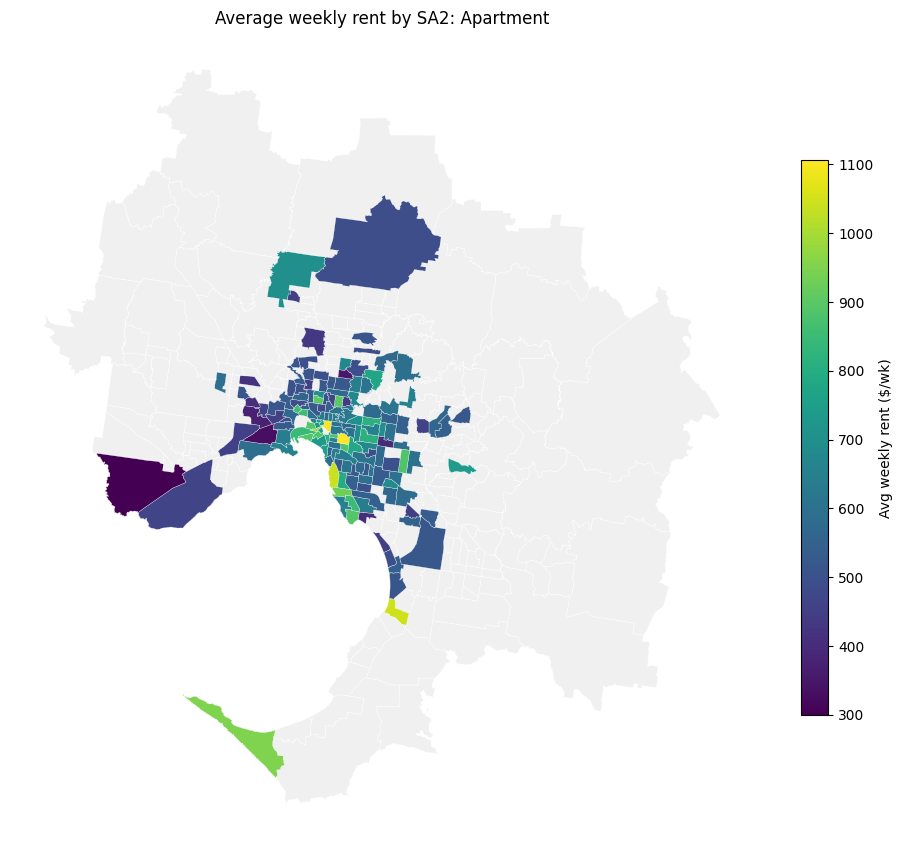

In [126]:
CHOSEN_PROPERTY_TYPES = "Apartment" # EDIT THIS

zones = gpd.read_file(DATA / "geospatial_data" / "Vic_Area_Zones" / "Vic_Area_Zones.shp")
zones = zones[zones["GCC_NAME21"] == "Greater Melbourne"]

subset = listings[listings["property_type"] == CHOSEN_PROPERTY_TYPES].copy()
points = gpd.GeoDataFrame(
    subset,
    geometry=gpd.points_from_xy(subset["longitude"], subset["latitude"]),
    crs="EPSG:4326",
).to_crs(zones.crs)

joined = gpd.sjoin(points, zones[["SA2_NAME21", "geometry"]], how="left", predicate="within")
rent_by_sa2 = (
    joined.groupby("SA2_NAME21")["weekly_rent_number"]
    .mean()
    .reset_index(name="avg_rent")
)

merged = zones.merge(rent_by_sa2, on="SA2_NAME21", how="left")
plot_data = merged[merged["avg_rent"].notna()]

fig, ax = plt.subplots(figsize=(12, 12))
merged.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="avg_rent",
    cmap="viridis",
    legend=True,
    legend_kwds={"label": "Avg weekly rent ($/wk)", "shrink": 0.6},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)
ax.set_title(f"Average weekly rent by SA2: {CHOSEN_PROPERTY_TYPES}")
ax.set_axis_off()
plt.show()

### Rent Per SA2 by Number of Bedrooms

In [127]:
zones = gpd.read_file(DATA / "geospatial_data" / "Vic_Area_Zones" / "Vic_Area_Zones.shp")
zones = zones[zones["GCC_NAME21"] == "Greater Melbourne"]

points = gpd.GeoDataFrame(
    listings,
    geometry=gpd.points_from_xy(listings["longitude"], listings["latitude"]),
    crs="EPSG:4326",
).to_crs(zones.crs)

joined = gpd.sjoin(points, zones[["SA2_NAME21", "geometry"]], how="inner", predicate="within")

rent_by_beds = joined.pivot_table(
    index="SA2_NAME21",
    columns="bedrooms",
    values="weekly_rent_number",
    aggfunc="median",
)
rent_by_beds.columns = [f"{int(c)} bed" for c in rent_by_beds.columns]
rent_by_beds

,0 bed,1 bed,2 bed,3 bed,4 bed,5 bed,6 bed,7 bed,8 bed,9 bed,50 bed
SA2_NAME21,,,,,,,,,,,
Abbotsford,NaN,525.0,680.0,1300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport West,NaN,NaN,535.0,695.0,850.0,NaN,NaN,NaN,NaN,NaN,NaN
Albert Park,NaN,600.0,740.0,1150.0,1750.0,NaN,NaN,NaN,NaN,NaN,NaN
Alphington - Fairfield,NaN,440.0,NaN,697.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Altona,NaN,NaN,545.0,700.0,900.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
Wollert,275.0,295.0,477.5,520.0,580.0,575.0,NaN,NaN,NaN,NaN,NaN
Wyndham Vale - North,NaN,350.0,425.0,450.0,485.0,610.0,NaN,NaN,NaN,NaN,NaN
Wyndham Vale - South,NaN,270.0,410.0,442.5,480.0,NaN,NaN,NaN,NaN,NaN,NaN


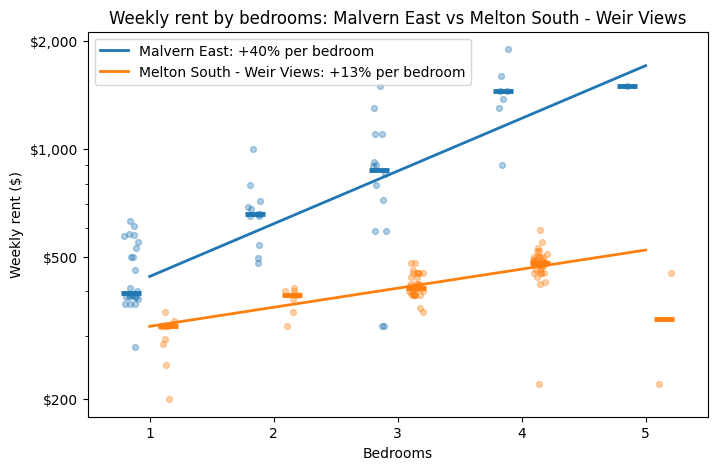

Log-linear fit: log(rent) ~ bedrooms
  Malvern East: slope=0.339, premium=+40.4% per bedroom, R^2=0.637 (n=58)
  Melton South - Weir Views: slope=0.123, premium=+13.1% per bedroom, R^2=0.406 (n=91)

Bedroom groups with n < 5:
  Malvern East, 5 bed: n=1
  Melton South - Weir Views, 5 bed: n=2

House vs Apartment/Unit split by bedrooms:
property_group                      House  Apartment/Unit  Other  total
SA2_NAME21                bedrooms                                     
Malvern East              1             1              23      0     24
                          2             1              11      0     12
                          3             5               7      2     14
                          4             4               1      2      7
                          5             1               0      0      1
Melton South - Weir Views 1             1               5      5     11
                          2             3               5      0      8
               

In [128]:
CHOSEN_SA2S = ["Malvern East", "Melton South - Weir Views"]  # EDIT THIS
BED_RANGE = np.arange(1, 6)
RNG = np.random.default_rng(42)
APT_UNIT = {"Apartment", "Unit", "Flat", "Studio", "Serviced Apartment"}

comp = joined[
    joined["SA2_NAME21"].isin(CHOSEN_SA2S)
    & joined["bedrooms"].between(1, 5)
    & joined["weekly_rent_number"].gt(0)
].copy()
comp["property_group"] = np.where(
    comp["property_type"].eq("House"), "House",
    np.where(comp["property_type"].isin(APT_UNIT), "Apartment/Unit", "Other"),
)

# Offsets so the two SA2s sit slightly left / right within each bedroom count
sa2_offset = {
    sa2: offset
    for sa2, offset in zip(CHOSEN_SA2S, [-0.15, 0.15][: len(CHOSEN_SA2S)])
}
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, ax = plt.subplots(figsize=(8, 5))
fit_stats = []

for i, sa2 in enumerate(CHOSEN_SA2S):
    grp = comp[comp["SA2_NAME21"] == sa2]
    color = colors[i % len(colors)]
    dx = sa2_offset[sa2]

    # Individual listings: jittered, semi-transparent dots
    x = grp["bedrooms"].to_numpy(dtype=float) + dx + RNG.uniform(-0.06, 0.06, size=len(grp))
    ax.scatter(x, grp["weekly_rent_number"], s=18, alpha=0.35, color=color, zorder=2)

    # Medians as short, thick horizontal ticks
    med = grp.groupby("bedrooms")["weekly_rent_number"].median()
    for beds, rent in med.items():
        ax.hlines(rent, beds + dx - 0.08, beds + dx + 0.08, colors=color, linewidth=3.5, zorder=4)

    # Fit log(rent) ~ bedrooms on individual listings; draw back-transformed curve
    beds = grp["bedrooms"].to_numpy(dtype=float)
    log_rent = np.log(grp["weekly_rent_number"].to_numpy(dtype=float))
    slope, intercept = np.polyfit(beds, log_rent, 1)
    y_hat = slope * beds + intercept
    ss_res = np.sum((log_rent - y_hat) ** 2)
    ss_tot = np.sum((log_rent - log_rent.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    pct = (np.exp(slope) - 1) * 100
    fit_stats.append({"sa2": sa2, "slope": slope, "pct": pct, "r2": r2, "n": len(grp)})

    xx = np.linspace(BED_RANGE.min(), BED_RANGE.max(), 100)
    ax.plot(xx, np.exp(intercept + slope * xx), color=color, linewidth=2,
            label=f"{sa2}: {pct:+.0f}% per bedroom", zorder=3)

ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xticks(BED_RANGE)
ax.set_xlim(0.5, 5.5)
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Weekly rent ($)")
ax.set_title("Weekly rent by bedrooms: Malvern East vs Melton South - Weir Views")
ax.legend()
plt.show()

# --- Diagnostics ---
print("Log-linear fit: log(rent) ~ bedrooms")
for s in fit_stats:
    print(f"  {s['sa2']}: slope={s['slope']:.3f}, "
          f"premium={s['pct']:+.1f}% per bedroom, R^2={s['r2']:.3f} (n={s['n']})")

print("\nBedroom groups with n < 5:")
counts = comp.groupby(["SA2_NAME21", "bedrooms"]).size().rename("n").reset_index()
sparse = counts[counts["n"] < 5]
if sparse.empty:
    print("  (none)")
else:
    for _, r in sparse.iterrows():
        print(f"  {r['SA2_NAME21']}, {int(r['bedrooms'])} bed: n={int(r['n'])}")

print("\nHouse vs Apartment/Unit split by bedrooms:")
split = (
    comp.groupby(["SA2_NAME21", "bedrooms", "property_group"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["House", "Apartment/Unit", "Other"], fill_value=0)
)
split["total"] = split.sum(axis=1)
print(split.to_string())
